# 発振器と定電圧

入力がなくても、自分で周期的な波を出し続ける回路を**発振器**といいます。測定器の信号発生器も発振器の一種です。正弦波、三角波、方形波、のこぎり波を出せる発振器を**関数発生器**(ファンクションジェネレータ)といいます。いちばん簡単な「信号源」として、一定の電圧を出す**定電圧源**もあわせて扱います。

この回では、4 つの波形、発振器の周波数の正確さ、定電圧の 3 つを見ます。

## 回路

![関数発生器](01_oscillator/circuit.svg)

積分器(4-1)とシュミットトリガ(5-1)を輪につないだ回路です。シュミットトリガの出力(方形波)を積分器が積分して三角波を作り、三角波がシュミットトリガのしきい値に届くと方形波が反転して、積分の向きが変わります。これをくり返して発振します。三角波を、ダイオードなどで丸めて正弦波にする回路もあります。

## 原理

**関数発生器**:方形波の電圧を $\pm V_s$、シュミットトリガのしきい値を $\pm V_s R_1 / R_2$ とすると、三角波はしきい値のあいだを傾き $V_s / (RC)$ で往復します。

$$\text{三角波の振幅} = V_s \frac{R_1}{R_2}, \qquad T = 4RC\,\frac{R_1}{R_2}$$

周期は R と C で決まり、振幅は R1 と R2 で決まります。

**Mimic の発振器(DDS)**:Mimic はアナログの輪ではなく、**DDS**(ダイレクト・デジタル・シンセシス)で波を作ります。5 µs ごとに「位相」の数に決まった値を足していき、位相から波形の値を計算します。足す値で周波数が決まり、0.05 mHz きざみで設定できます。周波数の正確さは、Mimic の時計(発振子)の正確さで決まります。

| 波形 | 形(どれも中心 Vref から始まって上がる) |
|---|---|
| 正弦波 | 1/4 周期で山、3/4 周期で谷 |
| 三角波 | 1/4 周期で山、3/4 周期で谷(直線) |
| 方形波 | 前半の半周期が High、後半が Low |
| のこぎり波 | 1 周期かけて下から上へ上がり、半周期のところで飛ぶ |

**定電圧源**:基準になる電圧(ツェナーダイオードやバンドギャップ基準)をボルテージフォロワで出す回路です。入力が何であっても、出力は決まった電圧のままです。

![発振器の 4 つの波形(模式図)](01_oscillator/response.svg)

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.oscillator(freq, amp, wave)` | `mimic.setOscillator(freq, amp, MIMIC_OSC_WAVE_SINE)` など | 周波数 f(Hz、= 1 / T)、振幅(ピーク、V)、波形 `"sine"`、`"triangle"`、`"square"`、`"sawtooth"` |
| `lab.mimic.constant_voltage(volts)` | `mimic.setConstantVoltage(volts)` | 出力の電圧(V) |

- 波の中心は Vref(2.5 V)です。出力は 0.1〜4.9 V までしか出ないので、振幅は 2.4 V までにします。
- 周波数や振幅を変えても、位相はとぎれずに続きます(アナログの発振器のつまみを回すのと同じ)。
- 方形波とのこぎり波は 1 サンプルのうちに飛ぶので、高い周波数では折り返し(4-3 のエイリアシング)の成分が混ざります。講義の周波数(数 kHz まで)では目立ちません。
- 発振器は入力を使いません。CH1 には信号発生器の出力が出ていますが、この回では見ません。

## 準備:測定器につなぐ

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, measure

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.4, mimic=20261125)

In [2]:
def show_out(t, ch2, label, ax=None):
    # The output only (the input is not used by the oscillator)
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(t * 1e3, ch2, color="C1", label=f"CH2: output ({label})")
    ax.set_xlabel("Time [ms]")
    ax.set_ylabel("Voltage [V]")
    ax.set_ylim(-0.2, 5.2)
    ax.grid(True)
    ax.legend(loc="upper right")
    if own:
        plt.show()

## 実験 1:4 つの波形

100 Hz、振幅 1 V で、4 つの波形を順に出します。どれも 1.5〜3.5 V のあいだを、0.1 秒に 10 回くり返すはずです。

sine     : 100.16 Hz, 1.497 - 3.494 V
triangle : 100.15 Hz, 1.500 - 3.490 V
square   : 100.15 Hz, 1.492 - 3.496 V
sawtooth : 100.12 Hz, 1.504 - 3.491 V


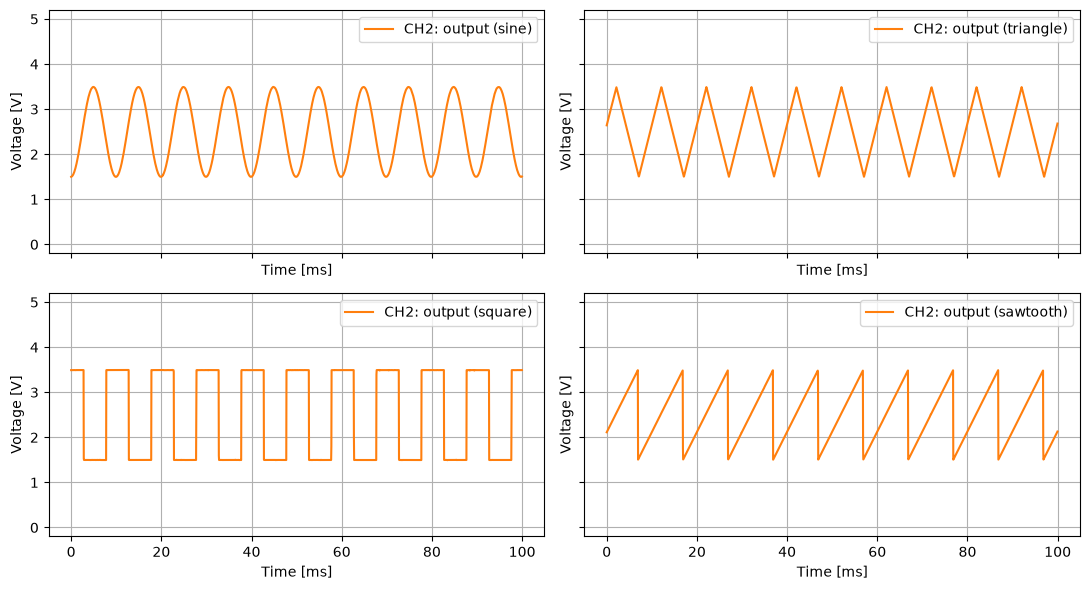

In [3]:
lab.fg.dc(2.5)
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True, sharey=True)
for ax, wave in zip(axes.flat, ("sine", "triangle", "square", "sawtooth")):
    lab.mimic.oscillator(100, 1.0, wave)
    time.sleep(0.1)
    t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s
    mean, freq = measure(t, ch2)
    print(f"{wave:9s}: {freq:.2f} Hz, {ch2.min():.3f} - {ch2.max():.3f} V")
    show_out(t, ch2, wave, ax)
plt.tight_layout()
plt.show()

取り込みは発振器と同期していないので、波がどこから始まるかは取り込むたびに変わります。

## 実験 2:周波数の正確さ

1 kHz の正弦波を出して、測定器で周波数を測ります。0.1 秒のあいだの約 100 周期から測ります。

measured 1001.37 Hz: +0.14 % from 1000 Hz


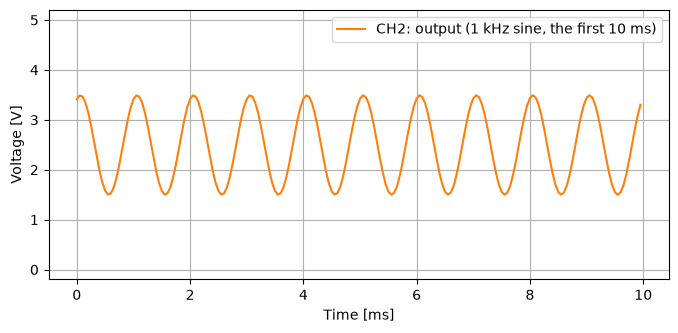

In [4]:
lab.mimic.oscillator(1000, 1.0, "sine")
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
mean, freq = measure(t, ch2)
print(f"measured {freq:.2f} Hz: {(freq / 1000 - 1) * 100:+.2f} % from 1000 Hz")
show_out(t[:200], ch2[:200], "1 kHz sine, the first 10 ms")

設定どおりの 1000 Hz から、0.1 % 程度ずれることがあります。Mimic(発振)と Arduino(測定)は、それぞれ自分の時計で動いていて、どちらにも小さな誤差があります。測った周波数は「Mimic の時計で 1000 Hz」を「Arduino の時計」で測った値なので、2 つの時計の比になります。正確な周波数が要るときは、水晶発振子を使った時計や、周波数カウンタで校正します。

## 実験 3:定電圧

入力に 100 Hz の正弦波を入れたまま、出力を 1.2 V の定電圧にします。入力が動いても、出力は 1.2 V のまま動かないはずです。

output 1.200 V (setting 1.2 V), noise 0.7 mV rms


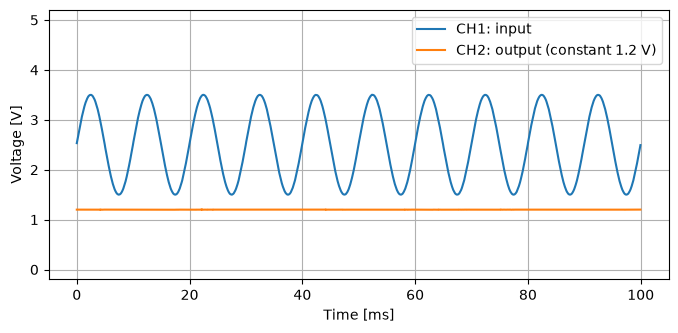

In [5]:
VOLTS = 1.2

lab.fg.sine(100, 1.0)
lab.mimic.constant_voltage(VOLTS)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"output {ch2.mean():.3f} V (setting {VOLTS} V), noise {ch2.std() * 1e3:.1f} mV rms")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (constant {VOLTS} V)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.set_ylim(-0.2, 5.2)
ax.grid(True)
ax.legend(loc="upper right")
plt.show()

定電圧は、ほかの回路の基準(比較器のしきい値など)や、センサーの電源に使います。Mimic では校正が効くので、設定した電圧が数 mV の誤差で出ます。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 波形と周波数を変える
<details><summary>ヒント</summary>

`WAVE` と `FREQ` を変えてみましょう。

- `WAVE` を `"sawtooth"` → `"square"` → `"triangle"`、`FREQ` を 50 → 200 → 1000 Hz。0.1 秒に入る周期の数は FREQ / 10 です。
- 1000 Hz の方形波やのこぎり波では、1 周期が測定器の 20 点しかないので、縁が少しなまって見えます(測定器の取り込みのため)。

</details>

measured 50.07 Hz


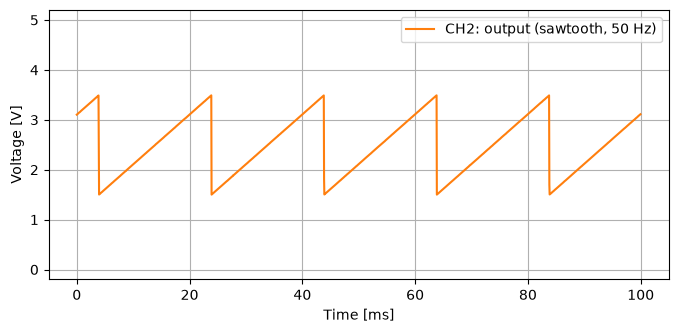

In [6]:
WAVE = "sawtooth"   # "sine", "triangle", "square" or "sawtooth"
FREQ = 50           # [Hz]

lab.fg.dc(2.5)
lab.mimic.oscillator(FREQ, 1.0, WAVE)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"measured {measure(t, ch2)[1]:.2f} Hz")
show_out(t, ch2, f"{WAVE}, {FREQ} Hz")

### 2. 振幅を変える
<details><summary>ヒント</summary>

`AMP` を 0.5 → 2.0 → 2.4 → 2.6 と変えてみましょう。

- 2.4 V までは、0.1〜4.9 V の範囲に収まります。
- 2.6 V では、山と谷が 0.1 V と 4.9 V で平らに切れます(0-1 で見た、出せる電圧の範囲)。

</details>

output 1.996 - 2.997 V (ideal 2.000 - 3.000 V)


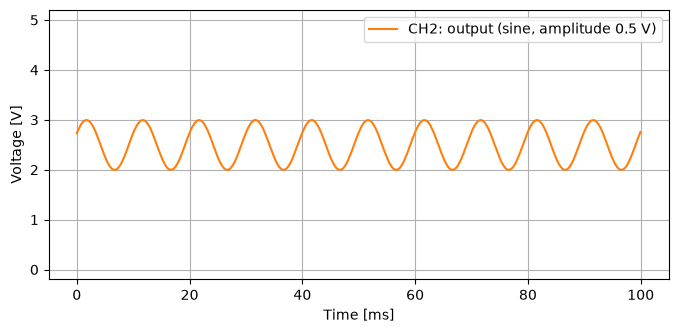

In [7]:
AMP = 0.5   # peak [V]

lab.mimic.oscillator(100, AMP, "sine")
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"output {ch2.min():.3f} - {ch2.max():.3f} V (ideal {2.5 - AMP:.3f} - {2.5 + AMP:.3f} V)")
show_out(t, ch2, f"sine, amplitude {AMP} V")

### 3. 定電圧の値を変える
<details><summary>ヒント</summary>

`VOLTS` を 3.3 → 0.05 → 4.95 と変えてみましょう。

- 3.3 V は、3.3 V で動く部品の電源や基準の代わりになります。
- 0.05 V と 4.95 V は、出せる範囲(0.1〜4.9 V)の外なので、出力はその手前で止まります。

</details>

In [8]:
VOLTS = 3.3

lab.mimic.constant_voltage(VOLTS)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"output {ch2.mean():.3f} V (setting {VOLTS} V)")

output 3.293 V (setting 3.3 V)


## まとめ

- 発振器は、入力なしで周期的な波を出す。関数発生器は、積分器とシュミットトリガの輪で三角波と方形波を作る(周期は RC で、振幅は抵抗の比で決まる)。
- Mimic の発振器は DDS で、5 µs ごとに位相を進めて波形を計算する。周波数の正確さは時計で決まる。
- 定電圧源は、入力によらず決まった電圧を出す。
- Mimic では `oscillator(freq, amp, wave)`、`constant_voltage(volts)`。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [9]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()